# Endterm PCA: engine characteristics

This training-only analysis uses `cylinders` and `displacement`. It describes variation among engines, rather than predicting MPG or proving that natural clusters exist.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display
from vehicle_efficiency.dimensionality_reduction import fit_pca, merge_cluster_assignments
from vehicle_efficiency.neural_network import load_training_data

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'pyproject.toml').exists())
results = ROOT / 'reports/results/endterm'
figures = ROOT / 'reports/figures/endterm'
train, _, manifest = load_training_data()
pipeline, variance, loadings, coordinates = fit_pca(train)
saved_variance = pd.read_csv(results / 'pca_variance.csv')
np.testing.assert_allclose(variance.explained_variance_ratio,
                           saved_variance.explained_variance_ratio)
assert set(coordinates.row_id) == set(train.row_id)

,component,explained_variance_ratio,cumulative_explained_variance
0,PC1,0.960637,0.960637
1,PC2,0.039363,1.000000


,PC1,PC2
feature,,
cylinders,0.707107,-0.707107
displacement,0.707107,0.707107


PC1 retains 96.06% of engine-feature variance.
PC1 + PC2 retain 100.00%.


,row_id,PC1
0,27059,-0.547589
1,27060,-0.931534
2,27062,-0.931534
3,27063,0.536302
4,27065,1.950296


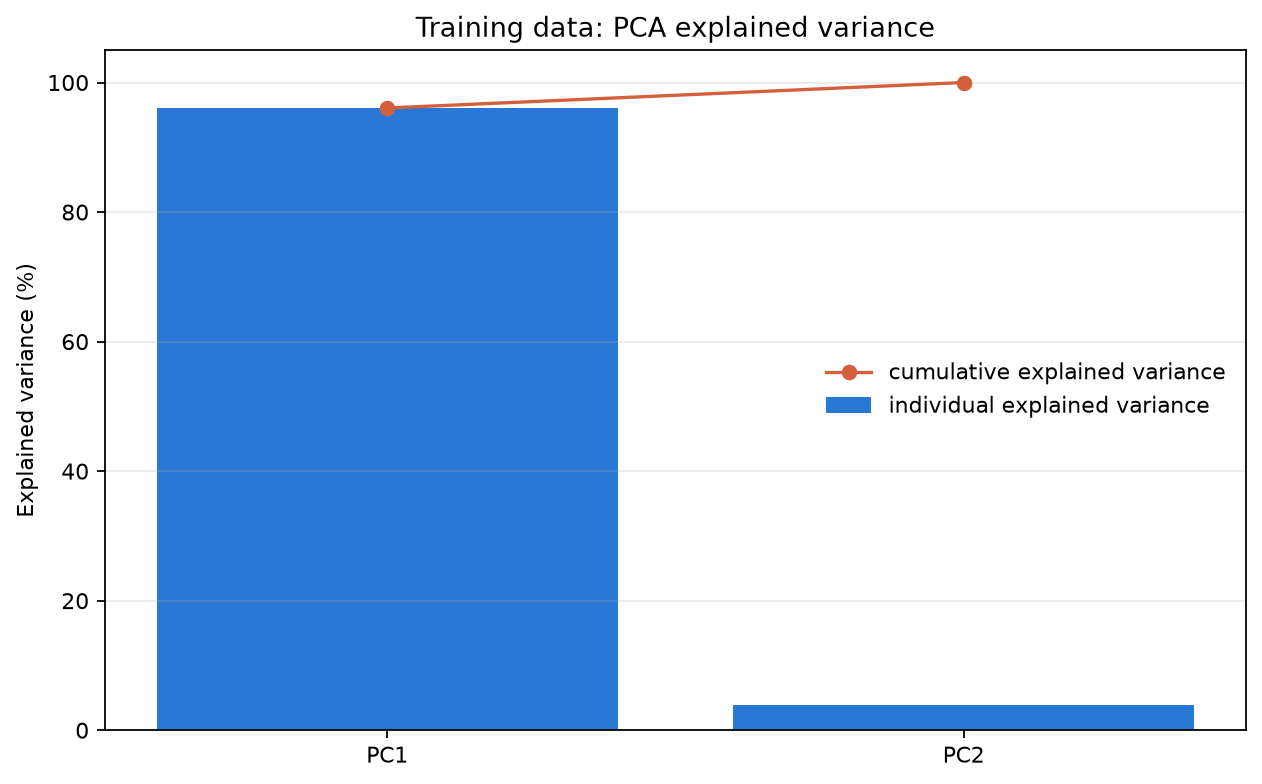

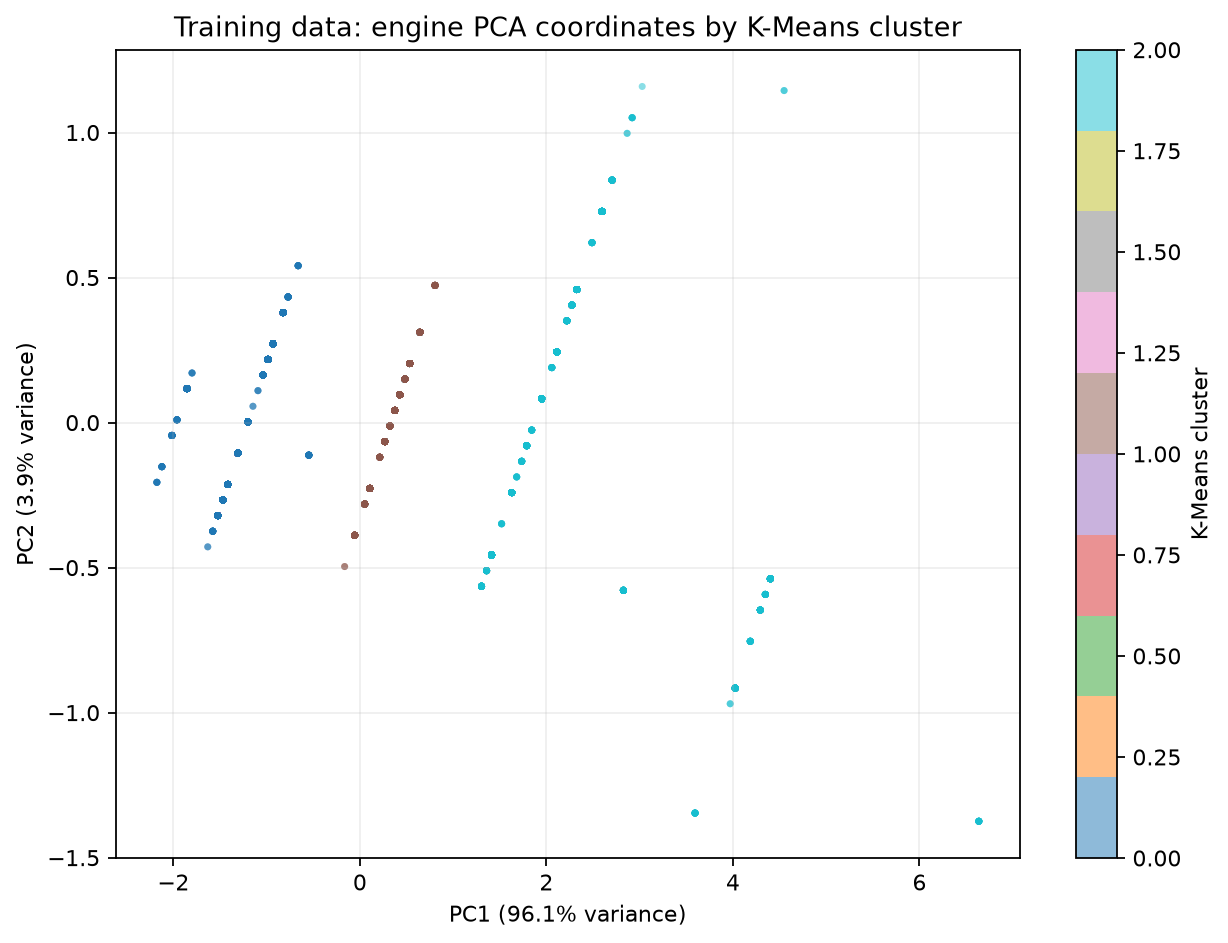

In [3]:
display(variance)
display(loadings)
print(f"PC1 retains {variance.loc[0, 'explained_variance_ratio']:.2%} of engine-feature variance.")
print(f"PC1 + PC2 retain {variance.loc[1, 'cumulative_explained_variance']:.2%}.")
display(coordinates[['row_id', 'PC1']].head())

assignments = pd.read_csv(results / 'clustering_assignments_train.csv')
overlay = merge_cluster_assignments(coordinates, assignments)
assert len(overlay) == len(train)
display(Image(filename=str(figures / 'pca_explained_variance.png')))
display(Image(filename=str(figures / 'pca_clusters_train.png')))

## Interpretation

Standardisation gives cylinders and displacement equal scale before PCA. PC1 has similar positive loadings for both variables, so it broadly separates jointly smaller and larger engines. Keeping only PC1 reduces two features to one while retaining 96.06% of their variance and discarding 3.94%. Keeping both components for the cluster scatter is a rotation of the original two-dimensional feature space.

The completed overlay joins saved K-Means assignments one-to-one on the exact training `row_id` set. It does not refit K-Means in PCA space. The notebook recomputes PCA in memory and checks the saved variance without overwriting experiment artifacts. PCA maximizes feature variance, not MPG accuracy, and does not establish natural clusters.